# A continuous tremor-dominance score

The analyses in `notebooks/` split patients at fixed cut-offs of the OFF-medication ratio of mean
tremor to mean bradykinesia MDS-UPDRS item scores (ratio < 0.8 bradykinesia-dominant, >= 1 tremor-dominant,
`TREM_VS_BRADY` in `config/main.yaml`). This folder uses the ratio itself instead.

**Why.** Splitting a continuous variable discards information and, with 11 and 10 patients, leaves
each group too small to say much on its own. The cut-off is also arbitrary relative to these data:
patients a few hundredths apart on the ratio can land in different groups. A correlation (or a
continuous moderator in the trial-level model) uses every patient's actual position on the
tremor-bradykinesia axis, and includes P24, the "intermediate" patient the split left out.

**The score** is `log2(tremor / bradykinesia)` from the OFF exam:

- OFF only, as for the subtype, so medication cannot move it.
- On the log scale because the raw ratio is strongly right-skewed (two patients above 3.5 would
  otherwise dominate any linear fit). 0 is the old tremor threshold, -0.32 the bradykinesia threshold,
  and one unit is a doubling of tremor relative to bradykinesia.
- Standardised across patients (`score_z`) where it enters a model.

This notebook describes the score and checks what else it travels with. The 19 UCLA and Case Western
patients have no MDS-UPDRS item scores, so no score-based analysis can include them.

Outputs go to `outputs/notebooks_2/` (gitignored). Nothing is written to the data directory.

In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
from imports import *

In [2]:
from config import dir_config, main_config
from src.utils.motor_score import OUTPUT_DIR, SCORE, correlate, motor_scores

processed_dir = Path(dir_config.data.processed)
metadata = pd.read_csv(processed_dir / "processed_metadata_all_data_accu_60.csv", encoding="latin1")
assert not str(OUTPUT_DIR).startswith(str(processed_dir.parents[0])), "never write to the data dir"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

scores = motor_scores(metadata)
thresholds = {label: np.log2(bounds[0]) for label, bounds in main_config.MDS_UPDRS.TREM_VS_BRADY.items() if bounds[0] > 0}
CATEGORY_COLOR = {"tremor": "#B5541D", "bradykinetic": "#4A5A6B", "intermediate": "#9A9A9A"}
print(f"{len(scores)} patients with an OFF-medication score; category thresholds on the log2 scale: {thresholds}")
scores.round(3)

22 patients with an OFF-medication score; category thresholds on the log2 scale: {'intermediate': np.float64(-0.3219280948873623), 'tremor': np.float64(0.0)}


,site,tremor_score,bradykinesia_score,trem_by_brady,category,UPDRS_off,off_med_first,off_meds_hrs,log2_trem_by_brady,score_z
subject_id,,,,,,,,,,
P22,Stanford,0.091,0.938,0.097,bradykinetic,22.0,1.0,24.00,-3.366,-2.121
P23,Stanford,0.182,1.188,0.153,bradykinetic,28.0,0.0,20.50,-2.707,-1.653
P1,Stanford,0.182,0.929,0.196,bradykinetic,18.0,1.0,24.00,-2.353,-1.400
P33,Harvard,0.091,0.375,0.242,bradykinetic,9.0,0.0,15.33,-2.044,-1.181
P20,Stanford,0.636,1.812,0.351,bradykinetic,39.0,0.0,23.50,-1.510,-0.801
P28,Harvard,0.182,0.438,0.416,bradykinetic,13.0,1.0,17.70,-1.267,-0.628
P13,Stanford,0.273,0.625,0.436,bradykinetic,13.0,1.0,25.00,-1.196,-0.578
P9,Stanford,0.727,1.250,0.582,bradykinetic,30.0,0.0,16.00,-0.781,-0.283
P34,Harvard,0.636,0.875,0.727,bradykinetic,22.0,1.0,15.50,-0.459,-0.054


## Distribution, and how close patients sit to the old cut-offs

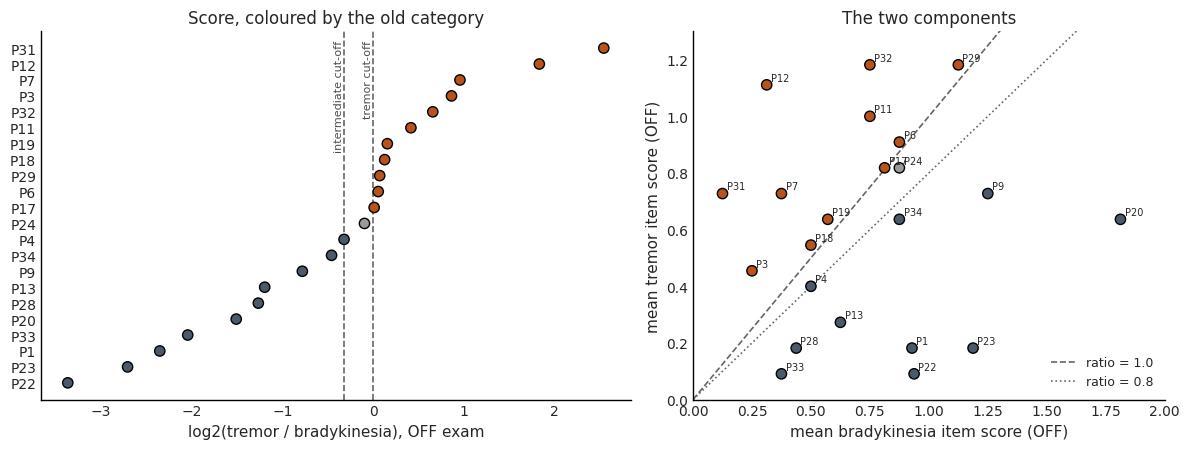

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})

ax = axes[0]
positions = np.arange(len(scores))
ax.scatter(scores[SCORE], positions, c=scores["category"].map(CATEGORY_COLOR), s=55, edgecolor="k", zorder=3)
for label, x in thresholds.items():
    ax.axvline(x, color="0.4", ls="--", lw=1.2)
    ax.annotate(f"{label} cut-off", (x, len(scores) - 0.5), rotation=90, ha="right", va="top", fontsize=8, color="0.3")
ax.set_yticks(positions)
ax.set_yticklabels(scores.index, fontsize=8)
ax.set_xlabel("log2(tremor / bradykinesia), OFF exam")
ax.set_title("Score, coloured by the old category", fontsize=12)

ax = axes[1]
ax.scatter(scores["bradykinesia_score"], scores["tremor_score"], c=scores["category"].map(CATEGORY_COLOR), s=55, edgecolor="k", zorder=3)
grid = np.linspace(0, 2, 50)
for ratio, style in [(1.0, "--"), (0.8, ":")]:
    ax.plot(grid, ratio * grid, color="0.4", ls=style, lw=1.2, label=f"ratio = {ratio}")
for participant, row in scores.iterrows():
    ax.annotate(participant, (row["bradykinesia_score"], row["tremor_score"]), xytext=(3, 3), textcoords="offset points", fontsize=7)
ax.set_xlim(0, 2)
ax.set_ylim(0, 1.3)
ax.set_xlabel("mean bradykinesia item score (OFF)")
ax.set_ylabel("mean tremor item score (OFF)")
ax.legend(frameon=False, fontsize=9)
ax.set_title("The two components", fontsize=12)

for a in axes:
    a.spines[["top", "right"]].set_visible(False)
    a.tick_params(labelsize=10)
    a.xaxis.label.set_size(11)
    a.yaxis.label.set_size(11)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "motor_score_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

In [4]:
near = scores[(scores[SCORE] - thresholds["tremor"]).abs() < np.log2(1.15)]
print(f"{len(near)} of {len(scores)} patients are within 15% of the ratio-1 cut-off: {list(near.index)}")
print(f"  of which {int((near['category'] == 'tremor').sum())} were labelled tremor-dominant")
scores[SCORE].describe().round(3)

6 of 22 patients are within 15% of the ratio-1 cut-off: ['P24', 'P17', 'P6', 'P29', 'P18', 'P19']
  of which 5 were labelled tremor-dominant


count    22.000
mean     -0.383
std       1.439
min      -3.366
25%      -1.249
50%      -0.043
75%       0.350
max       2.541
Name: log2_trem_by_brady, dtype: float64

## Does the ratio hold up ON medication?

The score is taken OFF medication by design. For reference, this compares it with the same ratio
from the ON exam. A modest agreement means the ratio is state-dependent (levodopa improves
bradykinesia and tremor by different amounts), so it should not be computed from the ON exam or
averaged across the two.

In [5]:
on = metadata[(metadata["treatment"] == "ON") & metadata["subject_id"].isin(scores.index)].set_index("subject_id")["trem_by_brady"]
stability = scores[["trem_by_brady"]].join(on.rename("trem_by_brady_on"))
stability = stability.replace(0, np.nan)
log_on = np.log2(stability["trem_by_brady_on"])
print(f"ON ratio available (and non-zero) for {log_on.notna().sum()} of {len(scores)}")
pd.Series(correlate(scores[SCORE], log_on.reindex(scores.index))).round(3)

ON ratio available (and non-zero) for 19 of 22


n                19.000
spearman rho      0.396
rho 2.5%         -0.029
rho 97.5%         0.725
p (perm, rho)     0.090
pearson r         0.396
p (perm, r)       0.090
dtype: float64

## What else the score travels with

The score is constant within a patient, so it cannot confound the OFF-versus-ON contrast directly.
It matters if it correlates with something that could itself change how medication affects prior
use. Those variables are tested as covariates in `2.28-covariate-adjusted-moderation`.

In [6]:
demographics = metadata[metadata["treatment"] == "OFF"].set_index("subject_id")[["age", "years_since_diagnosis", "MoCA", "Hoehn_and_Yahr_Stage", "gender"]]
table = scores.join(demographics)
for column in ["age", "years_since_diagnosis", "MoCA", "Hoehn_and_Yahr_Stage"]:
    table[column] = pd.to_numeric(table[column], errors="coerce")

continuous = ["UPDRS_off", "off_meds_hrs", "age", "years_since_diagnosis", "MoCA", "Hoehn_and_Yahr_Stage", "tremor_score", "bradykinesia_score"]
rows = []
for column in continuous:
    result = correlate(table[SCORE], table[column], n_boot=2000)
    rows.append({"variable": column, **{k: result[k] for k in ["n", "spearman rho", "rho 2.5%", "rho 97.5%", "p (perm, rho)"]}})

for column, label_map in [("site", None), ("off_med_first", {1.0: "OFF first", 0.0: "ON first"}), ("gender", None)]:
    groups = table[column].map(label_map) if label_map else table[column]
    levels = groups.dropna().unique()
    if len(levels) != 2:
        print(f"{column}: {len(levels)} levels, skipped")
        continue
    a, b = (table.loc[groups == level, SCORE] for level in levels)
    test = stats.mannwhitneyu(a, b)
    rows.append({"variable": f"{column} ({levels[0]} n={len(a)} vs {levels[1]} n={len(b)})", "n": len(a) + len(b),
                 "spearman rho": np.nan, "p (perm, rho)": test.pvalue,
                 "mean difference": a.mean() - b.mean()})

confounds = pd.DataFrame(rows).set_index("variable")
confounds.round(3)

,n,spearman rho,rho 2.5%,rho 97.5%,"p (perm, rho)",mean difference
variable,,,,,,
UPDRS_off,22,-0.246,-0.663,0.242,0.269,NaN
off_meds_hrs,22,-0.545,-0.821,-0.154,0.010,NaN
age,22,-0.069,-0.427,0.306,0.754,NaN
years_since_diagnosis,22,0.003,-0.464,0.464,0.990,NaN
MoCA,12,-0.283,-0.696,0.276,0.369,NaN
Hoehn_and_Yahr_Stage,14,-0.447,NaN,NaN,0.144,NaN
tremor_score,22,0.698,0.373,0.883,0.000,NaN
bradykinesia_score,22,-0.605,-0.855,-0.168,0.004,NaN
site (Stanford n=16 vs Harvard n=6),22,NaN,NaN,NaN,0.802,-0.411


For the two-group rows `p` is a Mann-Whitney U test and `mean difference` is the difference in mean
log2 ratio between the two levels.

`tremor_score` and `bradykinesia_score` are the score's own components, listed to show how much of
the variation in the ratio comes from each.

In [7]:
scores.to_csv(OUTPUT_DIR / "motor_scores.csv")
confounds.to_csv(OUTPUT_DIR / "motor_score_confounds.csv")
print(f"wrote {OUTPUT_DIR.relative_to(OUTPUT_DIR.parents[1])}/motor_scores.csv and motor_score_confounds.csv")

wrote outputs/notebooks_2/motor_scores.csv and motor_score_confounds.csv


## Results

Values are from this run; the score is a deterministic function of the metadata.

**The score is well spread.** log2(tremor / bradykinesia) runs from -3.37 (P22) to +2.54 (P31),
median -0.04, SD 1.44 (a 2.7-fold change in the ratio per SD).

**The old split sat in a crowded region.** Six of 22 patients are within 15% of the ratio-1 cut-off
(P24, P17, P6, P29, P18, P19). Five of them were labelled tremor-dominant and one (P24, 0.93) was
dropped as intermediate. A small change in one UPDRS item would move several of them across the line.

**The ratio is state-dependent.** OFF and ON ratios agree only modestly (rho = 0.40, n = 19, p = 0.09),
which supports anchoring the score on the OFF exam, as the categorical analysis did.

**Washout travels with the score.** More tremor-dominant patients had shorter OFF-medication washouts
(rho = -0.55 [-0.82, -0.15], permutation p = 0.01). This is the same imbalance `notebooks/2.32` found
between the subtypes, and it is the one covariate to keep in view (tested in `2.28`). Severity (UPDRS
OFF, rho = -0.25), age, disease duration, site, session order and sex are not detectably related to
the score at this n. Hoehn and Yahr (n = 14, three levels) and MoCA (n = 12) are too incomplete to say.

**Both components contribute.** The score correlates with tremor severity (rho = +0.70) and with
bradykinesia severity (rho = -0.61), and the two severities are unrelated to each other (rho = +0.04),
so the ratio is not a proxy for either one alone.